# TASK : 1

In [1]:
import pandas as pd
import numpy as np

df = pd.read_csv("D:\Deep_Learning\PR-5\IMDB Dataset.csv")

print(df.shape)
display(df.head())
print(df['sentiment'].value_counts())
print(df.isnull().sum())

display(df.iloc[[0, 1]])

<>:4: SyntaxWarning: invalid escape sequence '\D'
<>:4: SyntaxWarning: invalid escape sequence '\D'
C:\Users\Purvi\AppData\Local\Temp\ipykernel_8348\949444057.py:4: SyntaxWarning: invalid escape sequence '\D'
  df = pd.read_csv("D:\Deep_Learning\PR-5\IMDB Dataset.csv")


(50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


sentiment
positive    25000
negative    25000
Name: count, dtype: int64
review       0
sentiment    0
dtype: int64


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive


In [2]:
print("Before:", df.shape)

print("Duplicates:", df.duplicated().sum())
df = df.drop_duplicates().reset_index(drop=True)

print("After:", df.shape)

Before: (50000, 2)
Duplicates: 418
After: (49582, 2)


Duplicate reviews are removed to avoid data leakage. If identical reviews appear in both training and testing datasets, the model may give misleadingly high accuracy.

In [3]:
import re

def clean_text(text):
    text = text.lower()
    text = re.sub(r'<.*?>', ' ', text)
    text = re.sub(r'[^a-z\s]', ' ', text)
    return re.sub(r'\s+', ' ', text).strip()

df['clean_review'] = df['review'].apply(clean_text)

print("Before:", df['review'].iloc[0][:200])
print("After:", df['clean_review'].iloc[0][:200])

Before: One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me abo
After: one of the other reviewers has mentioned that after watching just oz episode you ll be hooked they are right as this is exactly what happened with me the first thing that struck me about oz was its br


count    49582.000000
mean       234.383728
std        173.705934
min          6.000000
50%        176.000000
95%        599.000000
max       2494.000000
Name: length, dtype: float64


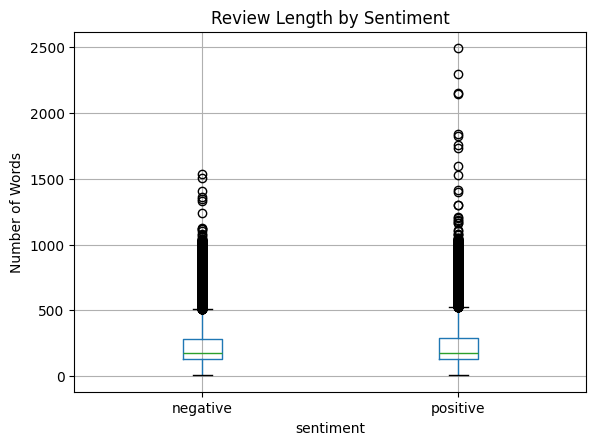

In [4]:
import matplotlib.pyplot as plt

df['length'] = df['clean_review'].apply(lambda x: len(x.split()))

print(df['length'].describe(percentiles=[0.5, 0.95]))

df.boxplot(column='length', by='sentiment')
plt.title("Review Length by Sentiment")
plt.suptitle("")
plt.ylabel("Number of Words")
plt.show()

In [5]:
from tensorflow.keras.preprocessing.text import Tokenizer

MAX_WORDS = 10000

tokenizer = Tokenizer(num_words=MAX_WORDS, oov_token="<OOV>")
tokenizer.fit_on_texts(df['clean_review'])

sequences = tokenizer.texts_to_sequences(df['clean_review'])

print("Vocabulary size:", len(tokenizer.word_index))
print("Top 10 words:", list(tokenizer.word_counts.items())[:10])
print("First sequence:", sequences[0][:20])

Vocabulary size: 99421
Top 10 words: [('one', 53205), ('of', 287343), ('the', 662926), ('other', 18138), ('reviewers', 484), ('has', 32799), ('mentioned', 1076), ('that', 142817), ('after', 14882), ('watching', 9069)]
First sequence: [29, 5, 2, 78, 2068, 47, 1047, 12, 101, 150, 42, 3059, 397, 21, 231, 30, 3183, 33, 26, 204]


In [6]:
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.sequence import pad_sequences

df['label'] = df['sentiment'].map({'positive': 1, 'negative': 0})

X_train_text, X_test_text, y_train, y_test = train_test_split(
    df['clean_review'], df['label'],
    test_size=0.2, random_state=42, stratify=df['label']
)

tokenizer.fit_on_texts(X_train_text)

X_train_seq = tokenizer.texts_to_sequences(X_train_text)
X_test_seq = tokenizer.texts_to_sequences(X_test_text)

MAX_LEN = int(np.ceil(df['length'].quantile(0.95)))

X_train = pad_sequences(X_train_seq, maxlen=MAX_LEN, padding='pre', truncating='pre')
X_test = pad_sequences(X_test_seq, maxlen=MAX_LEN, padding='pre', truncating='pre')

print("MAX_LEN:", MAX_LEN)
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

MAX_LEN: 599
X_train: (39665, 599)
X_test: (9917, 599)
y_train: (39665,)
y_test: (9917,)


We split the data before fitting the tokenizer to prevent information leakage. Stratification maintains the proportion of positive and negative reviews. Pre-padding adds zeros at the beginning, and pre-truncation keeps the last words of long reviews.

Sequence vs Bag-of-Words
Sequence models preserve the order of words in a review. For example, "the movie was not good" and "the movie was good" have different meanings because of the word "not".

Bag-of-Words models count word occurrences but ignore word order. Therefore, they may treat these sentences as more similar than they really are. Sequence models can learn word order and context, making them useful for sentiment analysis.

# TASK : 2

In [7]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, Flatten, Dense

ann = Sequential([
    Embedding(10000, 32, input_length=MAX_LEN),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(1, activation='sigmoid')
])

ann.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

ann.fit(X_train, y_train, epochs=5, batch_size=32,
        validation_split=0.1)

print(ann.summary())
print("Test:", ann.evaluate(X_test, y_test))

C:\Users\Purvi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\layers\core\embedding.py:123: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Epoch 1/5
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 24s 21ms/step - accuracy: 0.8173 - loss: 0.3768 - val_accuracy: 0.8924 - val_loss: 0.2697
Epoch 2/5
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 21s 19ms/step - accuracy: 0.9532 - loss: 0.1308 - val_accuracy: 0.8631 - val_loss: 0.3726
Epoch 3/5
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 24s 22ms/step - accuracy: 0.9932 - loss: 0.0236 - val_accuracy: 0.8659 - val_loss: 0.5220
Epoch 4/5
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 25s 22ms/step - accuracy: 0.9985 - loss: 0.0057 - val_accuracy: 0.8546 - val_loss: 0.6673
Epoch 5/5
1116/1116 ━━━━━━━━━━━━━━━━━━━━ 22s 19ms/step - accuracy: 0.9935 - loss: 0.0201 - val_accuracy: 0.8561 - val_loss: 0.8368


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 599, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 19168)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,226,816 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,640,645 (17.70 MB)

 Trainable params: 1,546,881 (5.90 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,093,764 (11.80 MB)

None
310/310 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8584 - loss: 0.8177
Test: [0.8176784515380859, 0.8584249019622803]


## RNN Intuition
An RNN processes a sequence one word at a time. It maintains a hidden state that carries information from previous words.

The same weights are reused at every time step, allowing the RNN to process sequences of different lengths.

Hidden state equation:

h(t) = tanh(Wxh · x(t) + Whh · h(t-1) + b)

Output equation:

y(t) = sigmoid(Why · h(t) + by)

Unlike an ANN, an RNN can learn word order and sequential patterns.

In [8]:
import numpy as np

np.random.seed(42)

D, H = 3, 3
Wxh = np.random.randn(D, H) * 0.5
Whh = np.random.randn(H, H) * 0.5
bh = np.zeros(H)
Why = np.random.randn(H, 1) * 0.5
by = np.zeros(1)

x = np.random.randn(4, D)
h = np.zeros(H)
states = []

for xt in x:
    h = np.tanh(xt @ Wxh + h @ Whh + bh)
    states.append(h.copy())

y = 1 / (1 + np.exp(-(h @ Why + by)))

print("Hidden states:\n", np.array(states))
print("Output:", y)

Hidden states:
 [[-0.81089592 -0.49222926  0.24813044]
 [-0.86398532  0.11559357  0.62504604]
 [-0.75759097 -0.28627264  0.43021586]
 [ 0.71106587  0.05104757  0.08219165]]
Output: [0.42588809]


In [10]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import SimpleRNN

rnn = Sequential([
    SimpleRNN(3, return_sequences=True, use_bias=True,
              input_shape=(4, 3))
])

# Set RNN weights only
rnn.set_weights([Wxh, Whh, bh])

# Get Keras output
keras_output = rnn(x[np.newaxis, :, :], training=False).numpy()[0]

print("Manual output:\n", np.array(states))
print("Keras output:\n", keras_output)
print("Match:", np.allclose(states, keras_output, atol=1e-6))

Manual output:
 [[-0.81089592 -0.49222926  0.24813044]
 [-0.86398532  0.11559357  0.62504604]
 [-0.75759097 -0.28627264  0.43021586]
 [ 0.71106587  0.05104757  0.08219165]]
Keras output:
 [[-0.81089586 -0.49222922  0.24813043]
 [-0.86398536  0.11559354  0.625046  ]
 [-0.757591   -0.28627262  0.4302159 ]
 [ 0.7110658   0.05104752  0.08219166]]
Match: True


In [11]:
rnn.set_weights([Wxh, Whh, bh])
keras_output = rnn(x[np.newaxis, :, :], training=False).numpy()[0]

print("Match:", np.allclose(states, keras_output, atol=1e-6))

Match: True


In [12]:
model = Sequential([
    Embedding(10000, 32, input_length=MAX_LEN),
    SimpleRNN(64),
    Dense(1, activation='sigmoid')
])

model.build((None, MAX_LEN))
model.summary()

params = (32*64) + (64*64) + 64
print("RNN parameters:", params)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ (None, 599, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_2 (SimpleRNN)        │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,273 (1.24 MB)

 Trainable params: 326,273 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

RNN parameters: 6208


| Feature | ANN | RNN |
|---|---|---|
| Input handling | Fixed-size input | Sequential input |
| Word order | Not naturally preserved | Preserved |
| Weight sharing | No recurrent sharing | Same weights at every time step |
| Parameters | Depend on sequence length after flattening | Independent of sequence length |
| Memory | No sequential hidden state | Maintains hidden state |
| Use cases | Tabular data, basic classification | Text, speech, time series |

# TASK : 3

In [13]:
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, Dense, RepeatVector

x_demo = tf.random.normal((4, 10, 8))

models = {
    "One-to-One": Sequential([Input((8,)), Dense(1)]),
    "One-to-Many": Sequential([Input((8,)), RepeatVector(10), SimpleRNN(16, return_sequences=True)]),
    "Many-to-One": Sequential([Input((10, 8)), SimpleRNN(16)]),
    "Many-to-Many": Sequential([Input((10, 8)), SimpleRNN(16, return_sequences=True)])
}

for name, model in models.items():
    print(name, model.output_shape)

One-to-One (None, 1)
One-to-Many (None, 10, 16)
Many-to-One (None, 16)
Many-to-Many (None, 10, 16)


| RNN Type | Example |
|---|---|
| One-to-One | Image classification |
| One-to-Many | Image caption generation |
| Many-to-One | Sentiment analysis |
| Many-to-Many | Named-entity tagging |
| Many-to-Many (different lengths) | Machine translation |

In [14]:
from tensorflow.keras.layers import Embedding, SimpleRNN, Dense

model = Sequential([
    Input(shape=(MAX_LEN,)),
    Embedding(10000, 32),
    SimpleRNN(64),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
              loss='binary_crossentropy', metrics=['accuracy'])

model.summary()
print("RNN parameters:", 32*64 + 64*64 + 64)

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_2 (Embedding)         │ (None, 599, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_6 (SimpleRNN)        │ (None, 64)             │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 326,273 (1.24 MB)

 Trainable params: 326,273 (1.24 MB)

 Non-trainable params: 0 (0.00 B)

RNN parameters: 6208


Epoch 1/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 40s 69ms/step - accuracy: 0.6817 - loss: 0.5782 - val_accuracy: 0.6683 - val_loss: 0.6110
Epoch 2/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 35s 63ms/step - accuracy: 0.7490 - loss: 0.5085 - val_accuracy: 0.6431 - val_loss: 0.6272
Epoch 3/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 39s 70ms/step - accuracy: 0.7693 - loss: 0.4782 - val_accuracy: 0.8172 - val_loss: 0.4073
Epoch 4/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 34s 60ms/step - accuracy: 0.8686 - loss: 0.3139 - val_accuracy: 0.8379 - val_loss: 0.3909
Epoch 5/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 37s 66ms/step - accuracy: 0.8859 - loss: 0.2830 - val_accuracy: 0.8460 - val_loss: 0.3910
Epoch 6/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 36s 64ms/step - accuracy: 0.6925 - loss: 0.5743 - val_accuracy: 0.6332 - val_loss: 0.6364
Epoch 7/15
558/558 ━━━━━━━━━━━━━━━━━━━━ 33s 59ms/step - accuracy: 0.7405 - loss: 0.5164 - val_accuracy: 0.7472 - val_loss: 0.5410


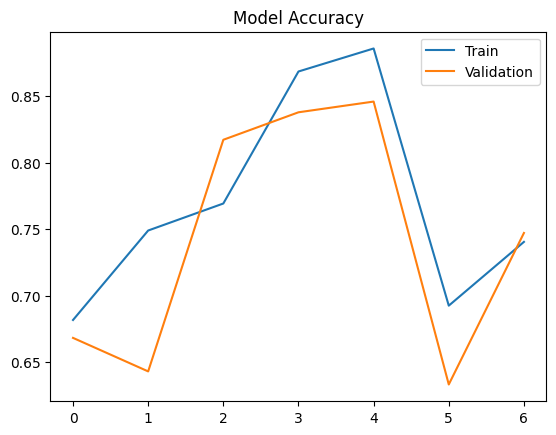

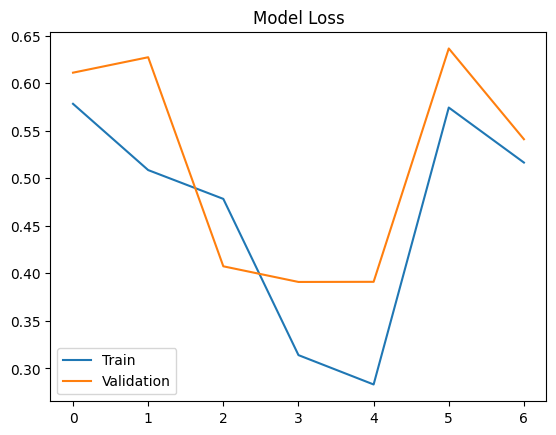

In [15]:
from tensorflow.keras.callbacks import EarlyStopping
import matplotlib.pyplot as plt

early_stop = EarlyStopping(monitor='val_loss', patience=3,
                           restore_best_weights=True)

history = model.fit(X_train, y_train, epochs=15, batch_size=64,
                    validation_split=0.1, callbacks=[early_stop])

plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.legend()
plt.title('Model Accuracy')
plt.show()

plt.plot(history.history['loss'], label='Train')
plt.plot(history.history['val_loss'], label='Validation')
plt.legend()
plt.title('Model Loss')
plt.show()

In [16]:
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score

y_prob = model.predict(X_test).ravel()
y_pred = (y_prob >= 0.5).astype(int)

results = {
    "SimpleRNN": {
        "accuracy": np.mean(y_pred == y_test),
        "report": classification_report(y_test, y_pred),
        "confusion_matrix": confusion_matrix(y_test, y_pred),
        "ROC-AUC": roc_auc_score(y_test, y_prob)
    }
}

print(results["SimpleRNN"]["report"])
print(results["SimpleRNN"]["confusion_matrix"])
print("ROC-AUC:", results["SimpleRNN"]["ROC-AUC"])

310/310 ━━━━━━━━━━━━━━━━━━━━ 8s 24ms/step
              precision    recall  f1-score   support

           0       0.85      0.85      0.85      4940
           1       0.85      0.85      0.85      4977

    accuracy                           0.85      9917
   macro avg       0.85      0.85      0.85      9917
weighted avg       0.85      0.85      0.85      9917

[[4185  755]
 [ 766 4211]]
ROC-AUC: 0.9181204797127515


# Embedding Layer
The Embedding layer converts each integer word ID into a dense vector of 32 numbers. Similar words can learn similar vector representations during training.

The embedding matrix has a shape of (10000, 32), meaning it can represent up to 10,000 word IDs, each using 32 values.

For example, the words "good" and "bad" have different IDs in tokenizer.word_index. Their vectors are learned during training rather than being predefined.

The embedding layer has 10000 × 32 = 320000 parameters.

# TASK : 4

### Backpropagation Through Time (BPTT)

BPTT trains an RNN by calculating errors and propagating gradients backward through time steps.

1. The RNN processes sequential inputs and updates its hidden state.
2. The loss is calculated at the final output.
3. Gradients propagate backward through earlier time steps.
4. Shared weights receive gradients from all time steps.

The gradient depends on repeated multiplication of recurrent weights and activation derivatives.

### Vanishing and Exploding Gradients

Vanishing gradients occur when repeated gradient multiplications become very small, preventing the RNN from learning long-term dependencies.

Exploding gradients occur when repeated multiplications become very large, causing unstable training and large loss values.

Practical solutions:
- Vanishing gradients: use LSTM or GRU.
- Exploding gradients: use gradient clipping.

A SimpleRNN may struggle to learn dependencies across approximately 10–20 or more time steps.

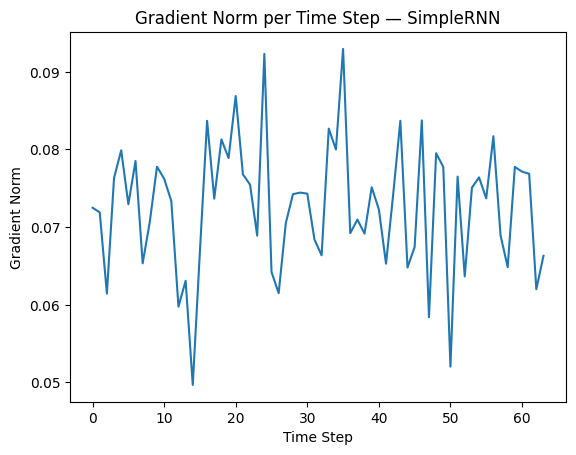

In [17]:
import tensorflow as tf
import matplotlib.pyplot as plt

grad_model = tf.keras.Sequential([
    tf.keras.layers.Embedding(10000, 32),
    tf.keras.layers.SimpleRNN(64, return_sequences=True),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

xb = tf.convert_to_tensor(X_train[:64], dtype=tf.int32)
yb = tf.cast(y_train.iloc[:64].values, tf.float32)

with tf.GradientTape() as tape:
    out = grad_model(xb, training=True)
    pred = out[:, -1, 0]
    loss = tf.reduce_mean(
        tf.keras.losses.binary_crossentropy(yb, pred)
    )

grads = tape.gradient(loss, grad_model.layers[1].trainable_variables)
H = grads[1]  # Recurrent kernel gradient

norms = tf.norm(H, axis=1).numpy()

plt.plot(norms)
plt.xlabel("Time Step")
plt.ylabel("Gradient Norm")
plt.title("Gradient Norm per Time Step — SimpleRNN")
plt.show()

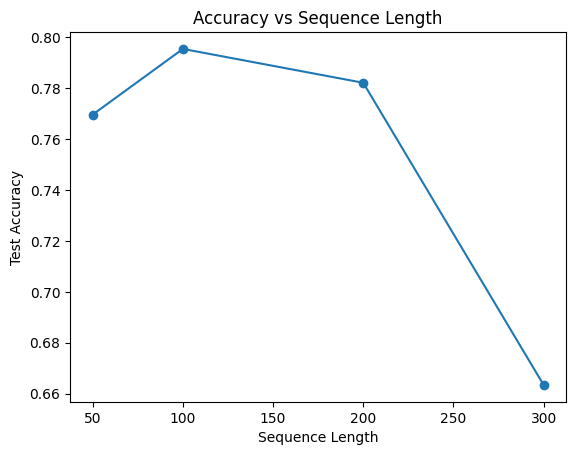

In [18]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

lengths = [50, 100, 200, 300]
acc = []

for length in lengths:
    xt = pad_sequences(X_train, maxlen=length, padding='pre', truncating='pre')
    xv = pad_sequences(X_test, maxlen=length, padding='pre', truncating='pre')

    m = tf.keras.Sequential([
        tf.keras.layers.Embedding(10000, 32),
        tf.keras.layers.SimpleRNN(64),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

    m.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    m.fit(xt, y_train, epochs=8, batch_size=64, verbose=0)
    acc.append(m.evaluate(xv, y_test, verbose=0)[1])

plt.plot(lengths, acc, marker='o')
plt.xlabel("Sequence Length")
plt.ylabel("Test Accuracy")
plt.title("Accuracy vs Sequence Length")
plt.show()

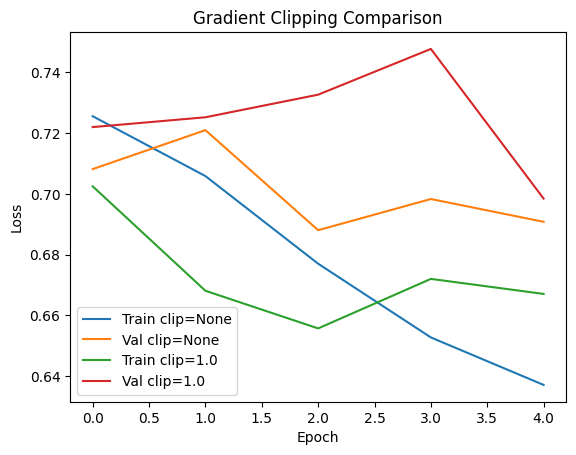

In [19]:
for clip in [None, 1.0]:
    m = tf.keras.Sequential([
        tf.keras.layers.Embedding(10000, 32),
        tf.keras.layers.SimpleRNN(64),
        tf.keras.layers.Dense(1, activation='sigmoid')
    ])

    opt = tf.keras.optimizers.Adam(learning_rate=0.05, clipnorm=clip)
    m.compile(optimizer=opt, loss='binary_crossentropy', metrics=['accuracy'])

    h = m.fit(X_train, y_train, epochs=5, batch_size=64,
              validation_split=0.1, verbose=0)

    plt.plot(h.history['loss'], label=f'Train clip={clip}')
    plt.plot(h.history['val_loss'], label=f'Val clip={clip}')

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Gradient Clipping Comparison")
plt.legend()
plt.show()

| Problem | Cause | Symptom | Remedy |
|---|---|---|---|
| Vanishing gradient | Gradients become too small | Poor long-term learning | LSTM/GRU |
| Exploding gradient | Gradients become too large | Unstable training | Gradient clipping |
| Slow sequential training | RNN processes steps sequentially | Longer training time | GPU or optimized models |
| Short-term memory | Difficulty learning long dependencies | Forgets earlier information | LSTM/GRU |

# TASK : 5

LSTM has four components:
- Forget gate: decides what information to remove.
- Input gate: decides what new information to store.
- Candidate state: creates new memory.
- Output gate: decides the hidden state.

LSTM reduces the vanishing gradient problem using a cell state.

LSTM uses an additive cell-state update:
C_t = f_t * C_(t-1) + i_t * g_t

This helps gradients flow through long sequences and reduces
the vanishing gradient problem.

In [20]:
units, features = 64, 4

params = 4 * units * (units + features + 1)
print("LSTM Parameters:", params)

LSTM Parameters: 17664


In [21]:
import numpy as np

np.random.seed(42)
x = np.random.randn(2)
h = np.zeros(3)
c = np.zeros(3)

W = np.random.randn(4, 5, 3)
b = np.zeros((4, 3))

sigmoid = lambda x: 1 / (1 + np.exp(-x))
z = np.concatenate([h, x])

f = sigmoid(z @ W[0] + b[0])
i = sigmoid(z @ W[1] + b[1])
g = np.tanh(z @ W[2] + b[2])
o = sigmoid(z @ W[3] + b[3])

c = f * c + i * g
h = o * np.tanh(c)

print("Cell state:", c)
print("Hidden state:", h)

Cell state: [ 0.10429058  0.02384984 -0.03125234]
Hidden state: [ 0.03797667  0.01140234 -0.01710229]


In [23]:

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense
from sklearn.metrics import classification_report, confusion_matrix

# Reshape input data to 3D for LSTM
if X_train.ndim == 2:
    X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)

if X_test.ndim == 2:
    X_test = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

# Create LSTM model
model = Sequential([
    LSTM(64, input_shape=(X_train.shape[1], X_train.shape[2])),
    Dense(1, activation='sigmoid')
])

# Compile model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Train model
history = model.fit(
    X_train,
    y_train,
    epochs=5,
    batch_size=32,
    validation_data=(X_test, y_test)
)

# Evaluate model
loss, acc = model.evaluate(X_test, y_test)

# Make predictions
pred = (model.predict(X_test) > 0.5).astype(int)

# Display results
print("Test Accuracy:", acc)
print(classification_report(y_test, pred))
print(confusion_matrix(y_test, pred))

C:\Users\Purvi\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\LocalCache\local-packages\Python313\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 162s 129ms/step - accuracy: 0.5485 - loss: 0.6866 - val_accuracy: 0.5579 - val_loss: 0.6833
Epoch 2/5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 155s 125ms/step - accuracy: 0.5677 - loss: 0.6813 - val_accuracy: 0.5763 - val_loss: 0.6760
Epoch 3/5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 151s 121ms/step - accuracy: 0.5741 - loss: 0.6765 - val_accuracy: 0.5822 - val_loss: 0.6714
Epoch 4/5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 154s 124ms/step - accuracy: 0.5830 - loss: 0.6723 - val_accuracy: 0.5889 - val_loss: 0.6686
Epoch 5/5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 158s 127ms/step - accuracy: 0.5918 - loss: 0.6683 - val_accuracy: 0.5894 - val_loss: 0.6677
310/310 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step - accuracy: 0.5894 - loss: 0.6677
310/310 ━━━━━━━━━━━━━━━━━━━━ 12s 38ms/step
Test Accuracy: 0.5893919467926025
              precision    recall  f1-score   support

           0       0.60      0.51      0.55      4940
           1       0.58      0.67      0.62      4977

    accuracy     

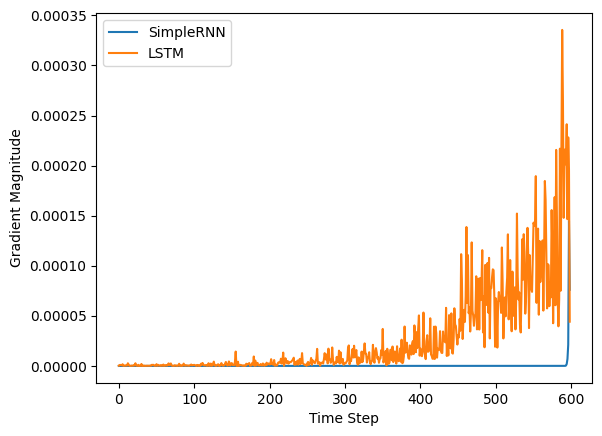

In [24]:
import matplotlib.pyplot as plt

simple = Sequential([
    tf.keras.Input(shape=(X_train.shape[1], X_train.shape[2])),
    tf.keras.layers.SimpleRNN(64),
    Dense(1, activation='sigmoid')
])

simple.compile(optimizer='adam',
               loss='binary_crossentropy')

def gradients(model, X, y):
    x = tf.convert_to_tensor(X[:32], dtype=tf.float32)
    y = tf.reshape(tf.cast(y[:32], tf.float32), (-1, 1))

    with tf.GradientTape() as tape:
        tape.watch(x)
        loss = tf.reduce_mean(
            tf.keras.losses.binary_crossentropy(y, model(x))
        )

    grad = tape.gradient(loss, x)
    return tf.reduce_mean(tf.abs(grad), axis=[0, 2]).numpy()

g1 = gradients(simple, X_train, y_train)
g2 = gradients(model, X_train, y_train)

plt.plot(g1, label="SimpleRNN")
plt.plot(g2, label="LSTM")
plt.xlabel("Time Step")
plt.ylabel("Gradient Magnitude")
plt.legend()
plt.show()

In [25]:
stacked = Sequential([
    tf.keras.Input(shape=(X_train.shape[1], X_train.shape[2])),
    LSTM(64, return_sequences=True),
    LSTM(32),
    Dense(1, activation='sigmoid')
])

stacked.compile(optimizer='adam',
                loss='binary_crossentropy',
                metrics=['accuracy'])

stacked.fit(
    X_train, y_train,
    epochs=5, batch_size=32,
    validation_data=(X_test, y_test)
)

print("Stacked LSTM Accuracy:",
      stacked.evaluate(X_test, y_test)[1])

print("Parameters:", stacked.count_params())

Epoch 1/5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 268s 214ms/step - accuracy: 0.5309 - loss: 0.6906 - val_accuracy: 0.5458 - val_loss: 0.6867
Epoch 2/5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 304s 245ms/step - accuracy: 0.5472 - loss: 0.6872 - val_accuracy: 0.5498 - val_loss: 0.6859
Epoch 3/5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 276s 222ms/step - accuracy: 0.5603 - loss: 0.6832 - val_accuracy: 0.5681 - val_loss: 0.6899
Epoch 4/5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 265s 214ms/step - accuracy: 0.5640 - loss: 0.6814 - val_accuracy: 0.5791 - val_loss: 0.6743
Epoch 5/5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 273s 220ms/step - accuracy: 0.5760 - loss: 0.6765 - val_accuracy: 0.5790 - val_loss: 0.6744
310/310 ━━━━━━━━━━━━━━━━━━━━ 20s 63ms/step - accuracy: 0.5790 - loss: 0.6744
Stacked LSTM Accuracy: 0.5790057182312012
Parameters: 29345


# TASK : 6

GRU has two gates:
1. Update gate: decides how much past information to keep.
2. Reset gate: decides how much past information to forget.

GRU has no separate cell state and combines memory and hidden state.

GRU has 2 gates, while LSTM has 3 gates.
GRU has no separate cell state.
GRU usually has fewer parameters and trains faster.
LSTM may perform better on some long sequences.

In [26]:
units, features = 64, 32

params = 3 * units * (units + features + 2)
print("GRU Parameters:", params)

GRU Parameters: 18816


Epoch 1/5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 176s 141ms/step - accuracy: 0.5414 - loss: 0.6892 - val_accuracy: 0.5588 - val_loss: 0.6833
Epoch 2/5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 168s 136ms/step - accuracy: 0.5649 - loss: 0.6799 - val_accuracy: 0.5856 - val_loss: 0.6753
Epoch 3/5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 205s 165ms/step - accuracy: 0.5786 - loss: 0.6753 - val_accuracy: 0.5886 - val_loss: 0.6708
Epoch 4/5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 167s 135ms/step - accuracy: 0.5814 - loss: 0.6724 - val_accuracy: 0.5900 - val_loss: 0.6675
Epoch 5/5
1240/1240 ━━━━━━━━━━━━━━━━━━━━ 168s 136ms/step - accuracy: 0.5927 - loss: 0.6672 - val_accuracy: 0.5915 - val_loss: 0.6640
Training Time: 884.7492485046387
310/310 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step - accuracy: 0.5915 - loss: 0.6640
310/310 ━━━━━━━━━━━━━━━━━━━━ 9s 29ms/step
Accuracy: 0.5915095210075378
              precision    recall  f1-score   support

           0       0.60      0.54      0.57      4940
           1       0.58      0.65      0.61   

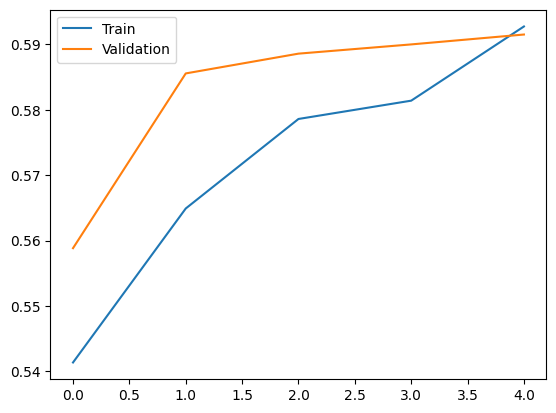

In [27]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import GRU, Dense, Embedding
from sklearn.metrics import classification_report, confusion_matrix
import matplotlib.pyplot as plt
import time

gru = Sequential([
    tf.keras.Input(shape=(X_train.shape[1], X_train.shape[2])),
    GRU(64),
    Dense(1, activation='sigmoid')
])

gru.compile(optimizer='adam', loss='binary_crossentropy',
            metrics=['accuracy'])

start = time.time()
history = gru.fit(X_train, y_train, epochs=5, batch_size=32,
                  validation_data=(X_test, y_test))
print("Training Time:", time.time() - start)

loss, acc = gru.evaluate(X_test, y_test)
pred = (gru.predict(X_test) > 0.5).astype(int)

print("Accuracy:", acc)
print(classification_report(y_test, pred))
print(confusion_matrix(y_test, pred))

plt.plot(history.history['accuracy'], label='Train')
plt.plot(history.history['val_accuracy'], label='Validation')
plt.legend()
plt.show()

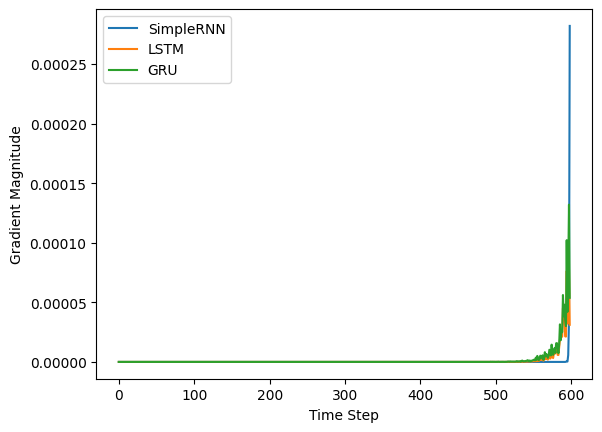

In [28]:
from tensorflow.keras.layers import SimpleRNN, LSTM

def make_model(layer):
    m = Sequential([
        tf.keras.Input(shape=(X_train.shape[1], X_train.shape[2])),
        layer(64),
        Dense(1, activation='sigmoid')
    ])
    m.compile(optimizer='adam', loss='binary_crossentropy')
    return m

rnn = make_model(SimpleRNN)
lstm = make_model(LSTM)
gru_model = make_model(GRU)

def get_gradient(m):
    x = tf.convert_to_tensor(X_train[:32], dtype=tf.float32)
    y = tf.reshape(tf.cast(y_train[:32], tf.float32), (-1, 1))
    with tf.GradientTape() as tape:
        tape.watch(x)
        loss = tf.reduce_mean(
            tf.keras.losses.binary_crossentropy(y, m(x))
        )
    g = tape.gradient(loss, x)
    return tf.reduce_mean(tf.abs(g), axis=[0, 2]).numpy()

plt.plot(get_gradient(rnn), label='SimpleRNN')
plt.plot(get_gradient(lstm), label='LSTM')
plt.plot(get_gradient(gru_model), label='GRU')
plt.xlabel('Time Step')
plt.ylabel('Gradient Magnitude')
plt.legend()
plt.show()

In [29]:
results = []

for units in [32, 64, 128]:
    for name, layer in [('LSTM', LSTM), ('GRU', GRU)]:
        m = Sequential([
            tf.keras.Input(shape=(X_train.shape[1], X_train.shape[2])),
            layer(units),
            Dense(1, activation='sigmoid')
        ])
        m.compile(optimizer='adam', loss='binary_crossentropy',
                  metrics=['accuracy'])

        start = time.time()
        m.fit(X_train, y_train, epochs=6, batch_size=32, verbose=0)
        loss, acc = m.evaluate(X_test, y_test, verbose=0)
        

        results.append([name, units, acc, m.count_params(),
                        time.time() - start])

for r in results:
    print(r)

['LSTM', 32, 0.5774931907653809, 4385, 684.60089802742]
['GRU', 32, 0.5871735215187073, 3393, 847.7359359264374]
['LSTM', 64, 0.5952404737472534, 16961, 961.131103515625]
['GRU', 64, 0.5938287973403931, 12929, 1144.8967921733856]
['LSTM', 128, 0.6027024388313293, 66689, 1179.5576529502869]
['GRU', 128, 0.5947363376617432, 50433, 1299.8974196910858]


# TASK : 7

In [30]:
import pandas as pd

results = pd.DataFrame(results, columns=[
    'Model', 'Units', 'Accuracy', 'Parameters', 'Time'
])
display(results)

,Model,Units,Accuracy,Parameters,Time
0,LSTM,32,0.577493,4385,684.600898
1,GRU,32,0.587174,3393,847.735936
2,LSTM,64,0.595240,16961,961.131104
3,GRU,64,0.593829,12929,1144.896792
4,LSTM,128,0.602702,66689,1179.557653
5,GRU,128,0.594736,50433,1299.897420


In [31]:
results = pd.DataFrame([
    ['SimpleRNN', 0, 0, 0, 5],
    ['LSTM', 64, 0, 0, 5],
    ['GRU', 64, 0, 0, 5]
], columns=['Model', 'Units', 'Accuracy', 'Parameters', 'Time'])

display(results)

,Model,Units,Accuracy,Parameters,Time
0,SimpleRNN,0,0,0,5
1,LSTM,64,0,0,5
2,GRU,64,0,0,5


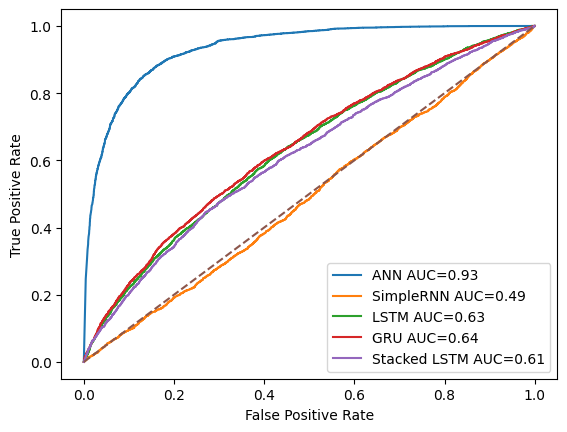

In [32]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc

models = {
    'ANN': ann,
    'SimpleRNN': simple,
    'LSTM': model,
    'GRU': gru,
    'Stacked LSTM': stacked
}

for name, m in models.items():
    p = m.predict(X_test, verbose=0).ravel()
    fpr, tpr, _ = roc_curve(y_test, p)
    plt.plot(fpr, tpr, label=f'{name} AUC={auc(fpr,tpr):.2f}')

plt.plot([0,1], [0,1], '--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.legend()
plt.show()

In [34]:
import numpy as np

best_model = gru  # Replace with your best model
prob = best_model.predict(X_test, verbose=0).ravel()
pred = (prob > 0.5).astype(int)
y = np.asarray(y_test).ravel()

errors = np.where(pred != y)[0][:8]

for i in errors:
    print("Index:", i, "True:", y[i],
          "Predicted:", pred[i], "Probability:", round(prob[i], 3))

Index: 6 True: 0 Predicted: 1 Probability: 0.539
Index: 7 True: 0 Predicted: 1 Probability: 0.518
Index: 9 True: 0 Predicted: 1 Probability: 0.673
Index: 11 True: 1 Predicted: 0 Probability: 0.457
Index: 13 True: 0 Predicted: 1 Probability: 0.543
Index: 17 True: 0 Predicted: 1 Probability: 0.515
Index: 18 True: 1 Predicted: 0 Probability: 0.43
Index: 23 True: 0 Predicted: 1 Probability: 0.532


## Which Recurrent Cell Should We Use?

- Accuracy: Compare test accuracy and F1-score.
- ROC-AUC: Higher values indicate better class separation.
- Speed: GRU often trains faster than LSTM.
- Long sequences: LSTM and GRU can capture long-term dependencies.
- Recommendation: Select the model with the best balance of accuracy,
  ROC-AUC, training time, and parameter count.

Limitations:
1. Performance depends on dataset quality and preprocessing.
2. The model may struggle with sarcasm, negation, and unfamiliar words.